# NYC Airbnb Listings: Exploring and Predicting Nightly Prices

Each row represents an Airbnb listing in New York City in 2019.
My goal is to explore how nightly prices vary by neighborhood and room type,
then build models that predict a listing’s nightly price in dollars.

In [3]:
import pandas as pd
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))
airbnb = pd.read_csv(filename)

print(f"{airbnb.shape[0]:,} listings | {airbnb.shape[1]} columns")
display(airbnb.head())

Saving AB_NYC_2019.csv to AB_NYC_2019.csv
48,895 listings | 16 columns


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.65,-73.97,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75,-73.98,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.81,-73.94,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.69,-73.96,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.80,-73.94,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [4]:
overview = pd.DataFrame({
    "data_type": airbnb.dtypes,
    "missing_rows": airbnb.isna().sum(),
    "missing_percent": (airbnb.isna().mean() * 100).round(2)
})

display(overview.sort_values("missing_rows", ascending=False))
print("Duplicate listing IDs:", airbnb["id"].duplicated().sum())
print("Listings priced at $0 or less:", airbnb["price"].le(0).sum())

,data_type,missing_rows,missing_percent
last_review,object,10052,20.56
reviews_per_month,float64,10052,20.56
host_name,object,21,0.04
name,object,16,0.03
id,int64,0,0.00
host_id,int64,0,0.00
neighbourhood_group,object,0,0.00
neighbourhood,object,0,0.00
latitude,float64,0,0.00
longitude,float64,0,0.00


Duplicate listing IDs: 0
Listings priced at $0 or less: 11


## Initial Data Exploration

The initial inspection found missing values in review information and listing
or host names, along with 11 listings priced at zero. No duplicate listing
IDs were found. I will examine distributions and relationships before
deciding how to clean these issues.

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

display(airbnb.describe().round(2))

display(
    airbnb.groupby("neighbourhood_group")["price"]
    .agg(["count", "median", "mean"])
    .round(2)
)

display(
    airbnb.groupby("room_type")["price"]
    .agg(["count", "median", "mean"])
    .round(2)
)

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,"48,895.00","48,895.00","48,895.00","48,895.00","48,895.00","48,895.00","48,895.00","38,843.00","48,895.00","48,895.00"
mean,"19,017,143.24","67,620,010.65",40.73,-73.95,152.72,7.03,23.27,1.37,7.14,112.78
std,"10,983,108.39","78,610,967.03",0.05,0.05,240.15,20.51,44.55,1.68,32.95,131.62
min,"2,539.00","2,438.00",40.50,-74.24,0.00,1.00,0.00,0.01,1.00,0.00
25%,"9,471,945.00","7,822,033.00",40.69,-73.98,69.00,1.00,1.00,0.19,1.00,0.00
50%,"19,677,284.00","30,793,816.00",40.72,-73.96,106.00,3.00,5.00,0.72,1.00,45.00
75%,"29,152,178.50","107,434,423.00",40.76,-73.94,175.00,5.00,24.00,2.02,2.00,227.00
max,"36,487,245.00","274,321,313.00",40.91,-73.71,"10,000.00","1,250.00",629.00,58.50,327.00,365.00


,count,median,mean
neighbourhood_group,,,
Bronx,1091,65.00,87.50
Brooklyn,20104,90.00,124.38
Manhattan,21661,150.00,196.88
Queens,5666,75.00,99.52
Staten Island,373,75.00,114.81


,count,median,mean
room_type,,,
Entire home/apt,25409,160.00,211.79
Private room,22326,70.00,89.78
Shared room,1160,45.00,70.13


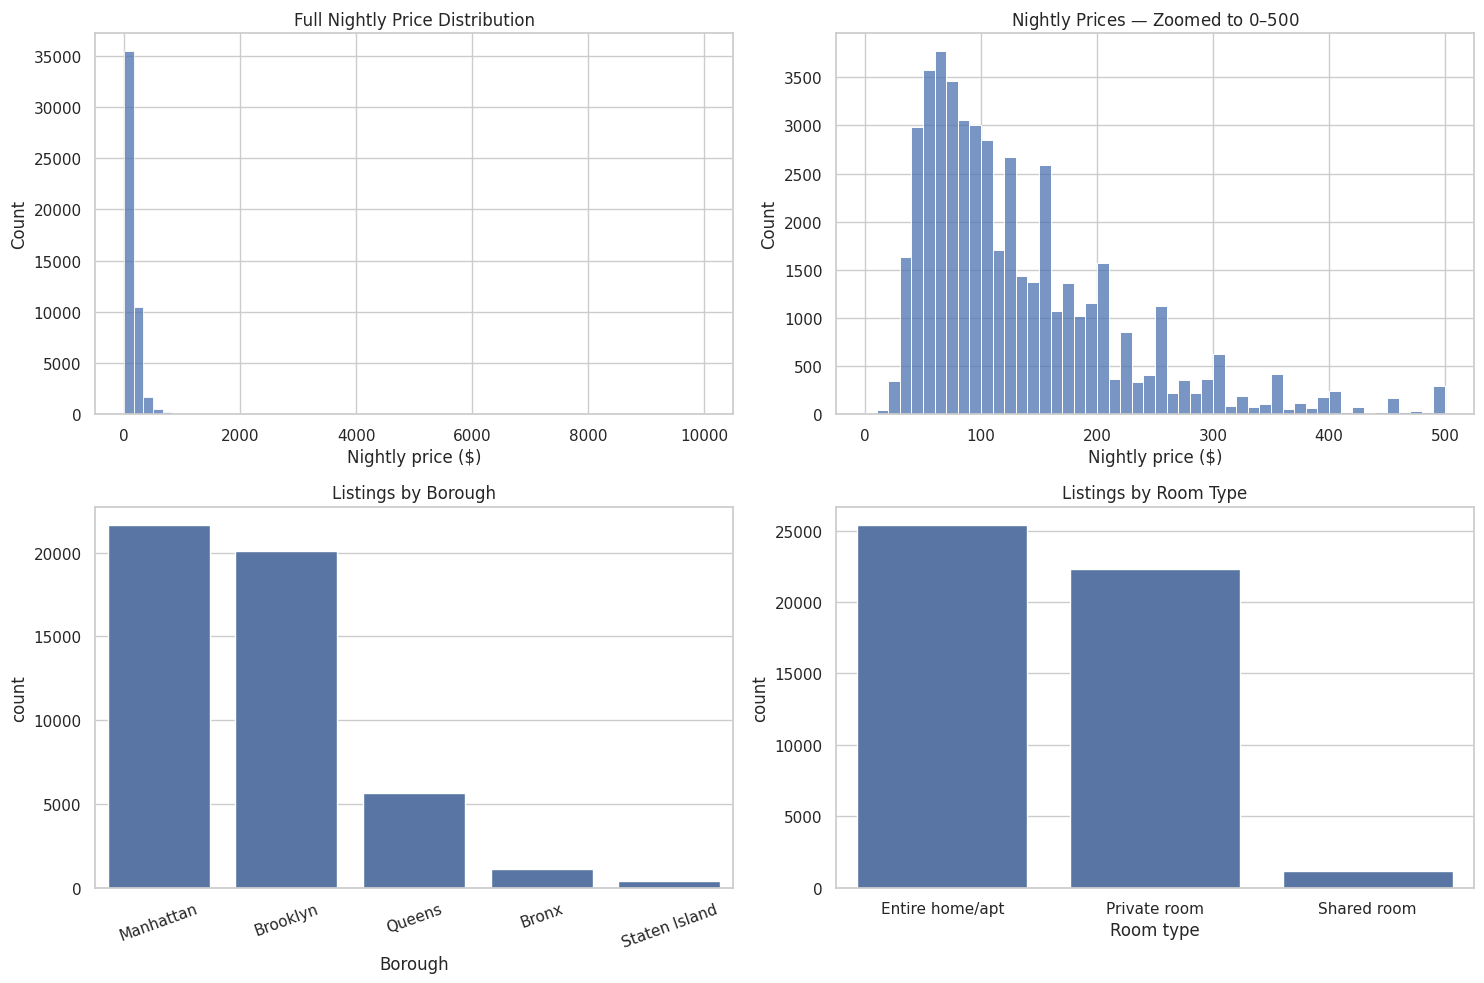

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.histplot(data=airbnb, x="price", bins=60, ax=axes[0, 0])
axes[0, 0].set_title("Full Nightly Price Distribution")
axes[0, 0].set_xlabel("Nightly price ($)")

sns.histplot(
    data=airbnb,
    x="price",
    binrange=(0, 500),
    bins=50,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Nightly Prices — Zoomed to $0–$500")
axes[0, 1].set_xlabel("Nightly price ($)")

sns.countplot(
    data=airbnb,
    x="neighbourhood_group",
    order=airbnb["neighbourhood_group"].value_counts().index,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Listings by Borough")
axes[1, 0].set_xlabel("Borough")
axes[1, 0].tick_params(axis="x", rotation=20)

sns.countplot(
    data=airbnb,
    x="room_type",
    order=airbnb["room_type"].value_counts().index,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Listings by Room Type")
axes[1, 1].set_xlabel("Room type")

plt.tight_layout()
plt.show()

## Initial Findings

The dataset contains 48,895 listings. The median nightly price is $106,
while the mean is $152.72. Prices reach $10,000, creating a long right tail
that pulls the mean above the median.

Manhattan and Brooklyn account for most listings. Manhattan has the highest
median nightly price at $150, followed by Brooklyn at $90. The Bronx has
the lowest median at $65.

Entire homes and apartments have a median price of $160, compared with $70
for private rooms and $45 for shared rooms. These differences suggest that
location and room type could help predict nightly prices.

Minimum stays reach 1,250 nights, which needs further investigation.
High prices and long minimum stays will be examined before deciding
whether they represent errors or valid unusual listings.

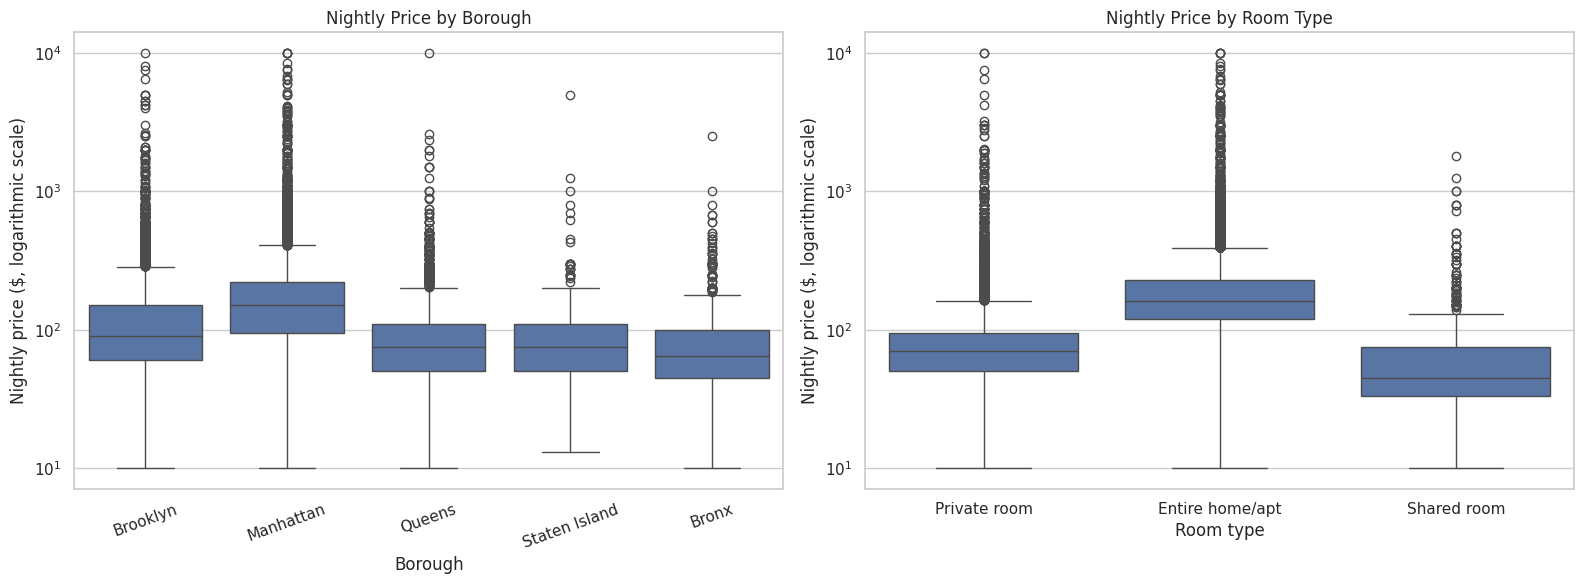

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

positive_prices = airbnb.loc[airbnb["price"] > 0]

sns.boxplot(
    data=positive_prices,
    x="neighbourhood_group",
    y="price",
    ax=axes[0]
)
axes[0].set_yscale("log")
axes[0].set_title("Nightly Price by Borough")
axes[0].set_xlabel("Borough")
axes[0].set_ylabel("Nightly price ($, logarithmic scale)")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(
    data=positive_prices,
    x="room_type",
    y="price",
    ax=axes[1]
)
axes[1].set_yscale("log")
axes[1].set_title("Nightly Price by Room Type")
axes[1].set_xlabel("Room type")
axes[1].set_ylabel("Nightly price ($, logarithmic scale)")

plt.tight_layout()
plt.show()

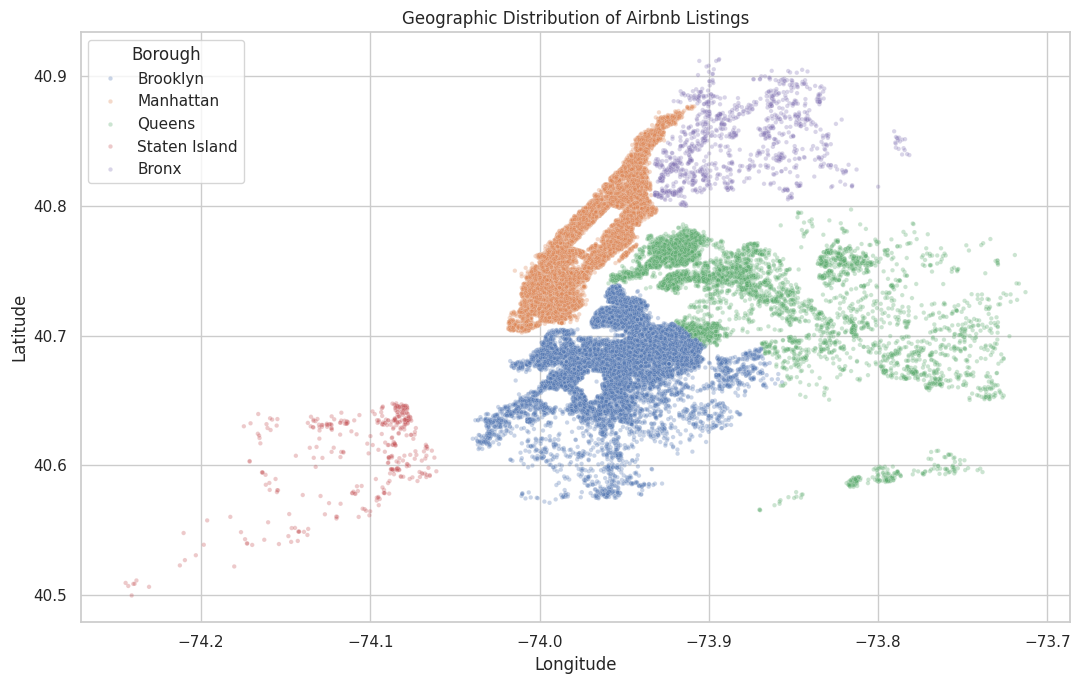

Monthly review rate is missing,False,True
Has zero reviews,,
False,38843,0
True,0,10052


In [8]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=airbnb,
    x="longitude",
    y="latitude",
    hue="neighbourhood_group",
    alpha=0.3,
    s=10
)

plt.title("Geographic Distribution of Airbnb Listings")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Borough")
plt.tight_layout()
plt.show()

review_check = pd.crosstab(
    airbnb["number_of_reviews"].eq(0),
    airbnb["reviews_per_month"].isna(),
    rownames=["Has zero reviews"],
    colnames=["Monthly review rate is missing"]
)

display(review_check)

## Price, Location, and Missing Review Findings

Manhattan and entire homes/apartments have higher typical nightly prices.
All boroughs and room types contain unusually expensive listings, so a
high price alone does not establish that a listing is incorrect.

The geographic plot shows dense concentrations in Manhattan and Brooklyn,
with listings distributed across all five boroughs.

All 10,052 missing monthly review rates correspond to listings with zero
reviews. I will fill these rates with zero to represent their recorded
review activity. Missing last-review dates will remain missing because
these listings have no recorded review date.

In [9]:
airbnb_clean = airbnb.copy()

rows_before = len(airbnb_clean)
airbnb_clean = airbnb_clean.loc[airbnb_clean["price"] > 0].copy()

no_reviews = (
    airbnb_clean["number_of_reviews"].eq(0)
    & airbnb_clean["reviews_per_month"].isna()
)
airbnb_clean.loc[no_reviews, "reviews_per_month"] = 0

airbnb_clean["name"] = airbnb_clean["name"].fillna("Unknown listing")
airbnb_clean["host_name"] = airbnb_clean["host_name"].fillna("Unknown host")

original_dates = airbnb_clean["last_review"].copy()
airbnb_clean["last_review"] = pd.to_datetime(
    original_dates,
    format="%Y-%m-%d",
    errors="coerce"
)

invalid_dates = (
    original_dates.notna() & airbnb_clean["last_review"].isna()
).sum()

print("Rows removed for nonpositive prices:", rows_before - len(airbnb_clean))
print("Remaining listings:", len(airbnb_clean))
print("Monthly review rates filled with zero:", no_reviews.sum())
print("Unparseable nonmissing review dates:", invalid_dates)

display(
    airbnb_clean.isna().sum()
    .rename("remaining_missing")
    .to_frame()
)

Rows removed for nonpositive prices: 11
Remaining listings: 48884
Monthly review rates filled with zero: 10051
Unparseable nonmissing review dates: 0


,remaining_missing
id,0
name,0
host_id,0
host_name,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


## Initial Cleaning Decisions

I excluded listings with nonpositive nightly prices from the paid-rental
prediction dataset. Missing monthly review rates were filled with zero
only where the listing had zero reviews. Missing listing and host names
received descriptive placeholders, and last-review dates were converted
to datetime values.

High positive prices and long minimum stays remain available for further
anomaly analysis. Any preprocessing learned from the data, including
scaling, feature selection, and anomaly thresholds, will be fitted using
the training data.

## Training, Validation, and Test Sets

I split the cleaned listings into approximately 60% training, 20% validation,
and 20% testing. Room-type proportions are preserved across the splits.

The training set will be used to fit preprocessing and models. The validation
set will support model comparison, and the test set will provide the final
evaluation after model selection.

This evaluates price prediction for held-out listings from the same 2019
snapshot. Some hosts may appear in multiple splits.

In [10]:
from sklearn.model_selection import train_test_split

train_df, remaining_df = train_test_split(
    airbnb_clean,
    test_size=0.40,
    random_state=42,
    stratify=airbnb_clean["room_type"]
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=42,
    stratify=remaining_df["room_type"]
)

split_summary = pd.DataFrame({
    "split": ["Training", "Validation", "Test"],
    "rows": [len(train_df), len(val_df), len(test_df)]
})

split_summary["percent"] = (
    split_summary["rows"] / len(airbnb_clean) * 100
).round(2)

display(split_summary)

assert set(train_df["id"]).isdisjoint(val_df["id"])
assert set(train_df["id"]).isdisjoint(test_df["id"])
assert set(val_df["id"]).isdisjoint(test_df["id"])
assert len(train_df) + len(val_df) + len(test_df) == len(airbnb_clean)

print("Verified: all listings assigned once, with no listing ID overlap.")

,split,rows,percent
0,Training,29330,60.00
1,Validation,9777,20.00
2,Test,9777,20.00


Verified: all listings assigned once, with no listing ID overlap.


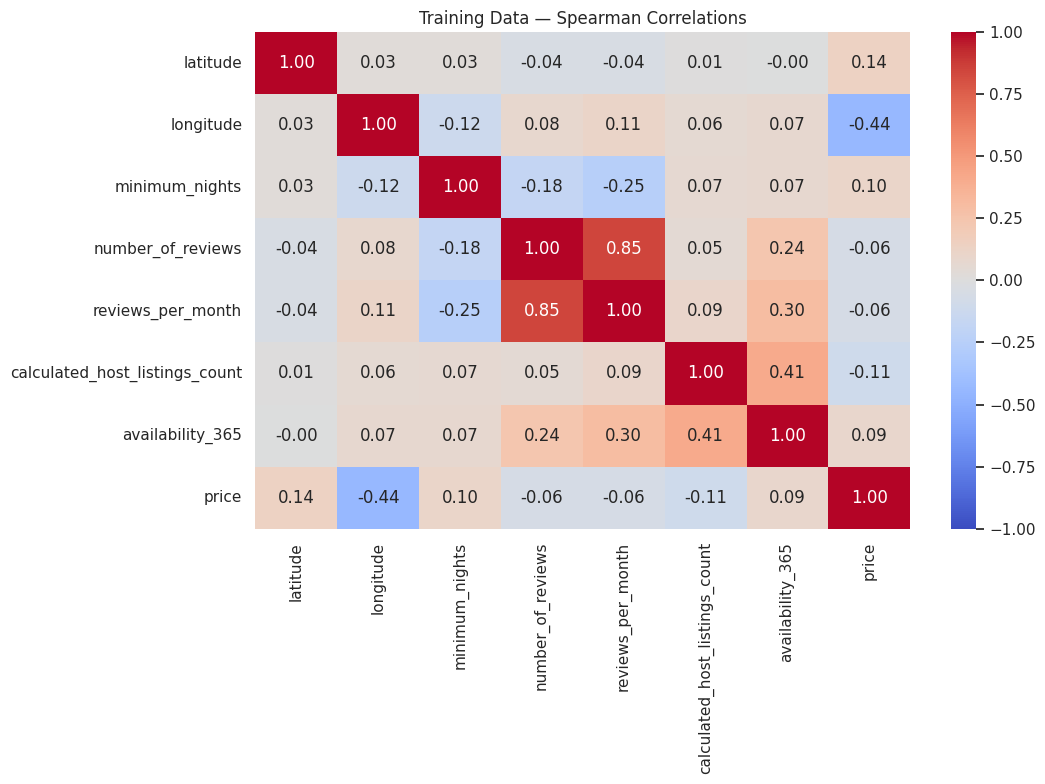

In [11]:
numeric_features = [
    "latitude",
    "longitude",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "price"
]

plt.figure(figsize=(11, 8))

sns.heatmap(
    train_df[numeric_features].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Training Data — Spearman Correlations")
plt.tight_layout()
plt.show()

## Clustering Similar Listings

I will use K-means to group listings using location, minimum stay, review
activity, host listing count, and availability. Nightly price is excluded
from clustering so the groups describe listing characteristics independently
of the prediction target.

Skewed count variables will receive a log transformation, followed by
standardization. Both preprocessing and clustering will be fitted on the
training set. I will compare 2–6 clusters using silhouette scores, which
measure how well the groups are separated.

In [12]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = [
    "latitude",
    "longitude",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

log_features = [
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count"
]

def prepare_cluster_features(frame):
    features = frame[cluster_features].copy()
    features[log_features] = np.log1p(features[log_features])
    return features

cluster_scaler = StandardScaler()

train_cluster_scaled = cluster_scaler.fit_transform(
    prepare_cluster_features(train_df)
)

cluster_models = {}
cluster_results = []

for k in range(2, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(train_cluster_scaled)

    score = silhouette_score(
        train_cluster_scaled,
        labels,
        sample_size=3000,
        random_state=42
    )

    cluster_models[k] = model
    cluster_results.append({
        "clusters": k,
        "silhouette_score": score
    })

cluster_results = pd.DataFrame(cluster_results)
display(cluster_results.round(4))

best_k = int(
    cluster_results.loc[
        cluster_results["silhouette_score"].idxmax(),
        "clusters"
    ]
)

cluster_model = cluster_models[best_k]
print("Selected number of clusters:", best_k)

,clusters,silhouette_score
0,2,0.24
1,3,0.28
2,4,0.28
3,5,0.26
4,6,0.22


Selected number of clusters: 4


,listing_count,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,price
cluster,,,,,,,,,
0,2124,40.72,-73.84,2.00,11.00,1.12,2.00,180.00,69.00
1,15185,40.72,-73.96,3.00,2.00,0.09,1.00,0.00,110.00
2,9522,40.72,-73.95,2.00,38.00,2.18,1.00,147.00,108.00
3,2499,40.75,-73.97,30.00,1.00,0.07,25.00,325.00,150.00


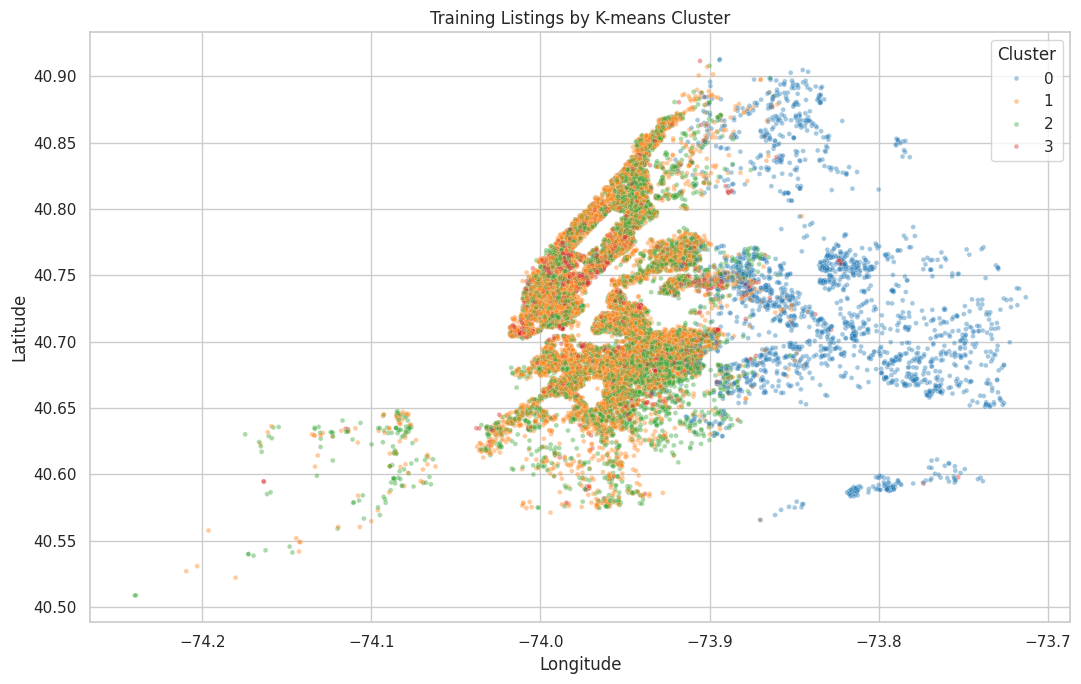

In [13]:
train_clustered = train_df.copy()
train_clustered["cluster"] = cluster_model.labels_

cluster_profile = train_clustered.groupby("cluster")[
    cluster_features + ["price"]
].median().round(2)

cluster_profile.insert(
    0,
    "listing_count",
    train_clustered.groupby("cluster").size()
)

display(cluster_profile)

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=train_clustered,
    x="longitude",
    y="latitude",
    hue="cluster",
    palette="tab10",
    alpha=0.4,
    s=12
)

plt.title("Training Listings by K-means Cluster")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## Clustering Findings

Four clusters achieved the highest sampled silhouette score of 0.2796,
although three clusters performed similarly at 0.2784. The score and
geographic overlap suggest modest separation.

Cluster 0 contains 2,124 listings with a median price of $69.
Cluster 1 is the largest group, with 15,185 listings, low median review
activity, and median availability of zero days.
Cluster 2 contains 9,522 listings with higher review activity, including
a median of 38 reviews and 2.18 reviews per month.
Cluster 3 contains 2,499 listings characterized by longer minimum stays
and hosts with more listings. Its median minimum stay is 30 nights,
median host listing count is 25, and median price is $150.

Availability of zero days describes the calendar snapshot and does not
establish whether a listing was fully booked or unavailable for another reason.

## Anomaly Detection and Training-Data Filtering

I will fit Isolation Forest on the training features used for clustering.
Price is excluded from anomaly detection. An initial contamination setting
of 0.01 identifies approximately 1% of training listings as unusual.

These flags identify unusual feature combinations and require interpretation.
I will create a filtered training dataset for comparison while retaining
the original training dataset. Validation and test listings will remain
available for evaluation across the full held-out population.

In [14]:
from sklearn.ensemble import IsolationForest

anomaly_model = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

anomaly_labels = anomaly_model.fit_predict(train_cluster_scaled)

anomaly_audit = train_clustered.copy()
anomaly_audit["is_anomaly"] = anomaly_labels == -1
anomaly_audit["anomaly_score"] = anomaly_model.decision_function(
    train_cluster_scaled
)

display(
    anomaly_audit.groupby("is_anomaly")
    .agg(
        listings=("id", "size"),
        median_price=("price", "median"),
        median_minimum_nights=("minimum_nights", "median"),
        median_reviews=("number_of_reviews", "median"),
        median_host_listings=("calculated_host_listings_count", "median"),
        median_availability=("availability_365", "median")
    )
    .round(2)
)

display(
    anomaly_audit.nsmallest(10, "anomaly_score")[
        [
            "id",
            "neighbourhood_group",
            "room_type",
            "price",
            "minimum_nights",
            "number_of_reviews",
            "calculated_host_listings_count",
            "availability_365",
            "anomaly_score"
        ]
    ]
)

train_filtered = train_df.loc[anomaly_labels == 1].copy()

print("Original training rows:", len(train_df))
print("Flagged training rows:", (anomaly_labels == -1).sum())
print("Filtered training rows:", len(train_filtered))

,listings,median_price,median_minimum_nights,median_reviews,median_host_listings,median_availability
is_anomaly,,,,,,
False,29036,105.00,3.00,5.00,1.00,44.00
True,294,132.50,2.00,7.00,279.50,318.50


,id,neighbourhood_group,room_type,price,minimum_nights,number_of_reviews,calculated_host_listings_count,availability_365,anomaly_score
7484,5581442,Queens,Private room,38,30,5,43,312,-0.06
18955,15054327,Queens,Private room,40,30,0,43,313,-0.06
15434,12368099,Queens,Private room,40,30,0,43,354,-0.06
27287,21550302,Queens,Private room,80,1,403,3,26,-0.06
7482,5581272,Queens,Private room,38,30,4,43,222,-0.06
28651,22176831,Queens,Private room,50,1,341,3,25,-0.05
20315,16233577,Queens,Private room,60,1,305,2,341,-0.05
22104,17779504,Queens,Private room,65,1,368,2,0,-0.05
29628,22750161,Queens,Private room,50,1,302,3,26,-0.05
40104,31123611,Queens,Shared room,40,1,65,8,346,-0.05


Original training rows: 29330
Flagged training rows: 294
Filtered training rows: 29036


## Anomaly Detection Findings

Isolation Forest flagged 294 training listings as unusual. Their median
host listing count was 279.5, compared with 1 for the remaining listings.
Their median availability was 318.5 days, compared with 44 days.

These patterns may represent commercial operators or unusual listing
activity. The flags do not establish that the records are incorrect.
I retained both training versions so validation results can show whether
filtering improves prediction.

## Feature Engineering and Processing

I will create an indicator for listings with no reviews and log-transform
skewed count variables. Cluster membership will provide an additional
categorical feature.

Listing IDs, host IDs, names, and raw review dates are excluded from this
initial model. Geographic coordinates, neighborhood, borough, and room
type remain available.

Numeric features will be standardized and categorical features one-hot
encoded. Preprocessing will be fitted on the original training set and
applied consistently to the filtered training and validation sets.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

def build_model_features(frame):
    features = frame[
        [
            "latitude",
            "longitude",
            "availability_365",
            "neighbourhood_group",
            "neighbourhood",
            "room_type"
        ]
    ].copy()

    for column in log_features:
        features[f"log_{column}"] = np.log1p(frame[column])

    features["has_no_reviews"] = (
        frame["number_of_reviews"].eq(0).astype(int)
    )

    scaled_features = cluster_scaler.transform(
        prepare_cluster_features(frame)
    )
    features["cluster"] = (
        cluster_model.predict(scaled_features).astype(str)
    )

    return features

X_train = build_model_features(train_df)
X_train_filtered = build_model_features(train_filtered)
X_val = build_model_features(val_df)

y_train = train_df["price"].copy()
y_train_filtered = train_filtered["price"].copy()
y_val = val_df["price"].copy()

categorical_columns = [
    "neighbourhood_group",
    "neighbourhood",
    "room_type",
    "cluster"
]

numeric_columns = [
    column for column in X_train.columns
    if column not in categorical_columns
]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_columns),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    ]
)

X_train_ready = preprocessor.fit_transform(X_train)
X_train_filtered_ready = preprocessor.transform(X_train_filtered)
X_val_ready = preprocessor.transform(X_val)

print("Training feature matrix:", X_train_ready.shape)
print("Filtered training feature matrix:", X_train_filtered_ready.shape)
print("Validation feature matrix:", X_val_ready.shape)
print("Missing training feature values:", X_train.isna().sum().sum())

display(X_train.head())

Training feature matrix: (29330, 235)
Filtered training feature matrix: (29036, 235)
Validation feature matrix: (9777, 235)
Missing training feature values: 0


,latitude,longitude,availability_365,neighbourhood_group,neighbourhood,room_type,log_minimum_nights,log_number_of_reviews,log_reviews_per_month,log_calculated_host_listings_count,has_no_reviews,cluster
48477,40.73,-73.98,33,Manhattan,Gramercy,Entire home/apt,2.40,0.00,0.00,0.69,1,1
26206,40.81,-73.95,245,Manhattan,Harlem,Entire home/apt,1.61,2.30,0.66,0.69,0,2
35287,40.66,-73.94,90,Brooklyn,East Flatbush,Private room,1.39,1.39,0.25,1.79,0,1
1311,40.69,-73.95,245,Brooklyn,Bedford-Stuyvesant,Private room,3.43,3.74,0.50,2.20,0,3
42834,40.76,-73.81,204,Queens,Flushing,Private room,0.69,2.30,1.26,1.95,0,0


## Feature Selection and Anomaly-Filtering Comparison

I will rank encoded features by their individual linear association with
log-transformed price, using only the training data. A candidate feature
set will retain the highest-scoring 75% of features.

I will compare four Ridge regression configurations using all or selected
features, with the original or anomaly-filtered training data. Validation
MAE will determine the best configuration for this preliminary comparison.
RMSE will also be reported to show sensitivity to large prediction errors.

This selection method measures individual linear relationships and may
miss useful nonlinear effects or interactions.

In [16]:
from sklearn.feature_selection import SelectPercentile, f_regression
from sklearn.linear_model import Ridge
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

feature_selector = SelectPercentile(
    score_func=f_regression,
    percentile=75
)

X_train_selected = feature_selector.fit_transform(
    X_train_ready,
    np.log1p(y_train)
)

X_train_filtered_selected = feature_selector.transform(
    X_train_filtered_ready
)
X_val_selected = feature_selector.transform(X_val_ready)

feature_names = preprocessor.get_feature_names_out()
selected_feature_names = feature_names[
    feature_selector.get_support()
]

print("Original features:", len(feature_names))
print("Selected features:", len(selected_feature_names))

feature_ranking = pd.DataFrame({
    "feature": feature_names,
    "score": feature_selector.scores_,
    "selected": feature_selector.get_support()
}).sort_values("score", ascending=False)

display(feature_ranking.head(20))

Original features: 235
Selected features: 176


,feature,score,selected
228,categorical__room_type_Entire home/apt,"17,965.07",True
229,categorical__room_type_Private room,"13,733.47",True
10,categorical__neighbourhood_group_Manhattan,"4,028.76",True
1,numeric__longitude,"3,600.23",True
9,categorical__neighbourhood_group_Brooklyn,"1,123.86",True
11,categorical__neighbourhood_group_Queens,"1,047.20",True
230,categorical__room_type_Shared room,927.14,True
138,categorical__neighbourhood_Midtown,881.93,True
231,categorical__cluster_0,775.58,True
41,categorical__neighbourhood_Bushwick,656.55,True


In [17]:
configurations = [
    (
        "Original training / all features",
        X_train_ready,
        y_train,
        X_val_ready
    ),
    (
        "Original training / selected features",
        X_train_selected,
        y_train,
        X_val_selected
    ),
    (
        "Filtered training / all features",
        X_train_filtered_ready,
        y_train_filtered,
        X_val_ready
    ),
    (
        "Filtered training / selected features",
        X_train_filtered_selected,
        y_train_filtered,
        X_val_selected
    )
]

comparison_rows = []
preliminary_models = {}

baseline_predictions = np.full(len(y_val), y_train.median())

comparison_rows.append({
    "configuration": "Training-median baseline",
    "MAE": mean_absolute_error(y_val, baseline_predictions),
    "RMSE": np.sqrt(
        mean_squared_error(y_val, baseline_predictions)
    )
})

for name, training_features, training_target, validation_features in configurations:
    model = TransformedTargetRegressor(
        regressor=Ridge(alpha=10.0, solver="lsqr"),
        func=np.log1p,
        inverse_func=np.expm1
    )

    model.fit(training_features, training_target)

    predictions = np.maximum(
        model.predict(validation_features),
        0
    )

    preliminary_models[name] = model

    comparison_rows.append({
        "configuration": name,
        "MAE": mean_absolute_error(y_val, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_val, predictions)
        )
    })

preliminary_results = pd.DataFrame(comparison_rows).sort_values("MAE")

display(preliminary_results.round(2))

,configuration,MAE,RMSE
3,Filtered training / all features,55.70,173.70
1,Original training / all features,55.71,173.70
4,Filtered training / selected features,55.74,173.68
2,Original training / selected features,55.74,173.69
0,Training-median baseline,79.21,193.66


## Preliminary Modeling Findings

The filtered training dataset with all 235 encoded features achieved the
lowest validation MAE of $55.70. The training-median baseline achieved
$79.21, so the model reduced MAE by approximately 29.7%.

Anomaly filtering changed MAE by only about one cent. Selecting 176
features slightly increased MAE. These results provide little evidence
of a meaningful benefit from filtering or this feature-selection method.

For the next modeling stage, I will use the filtered training rows and
the full engineered feature set, allowing AutoViML to perform its own
feature selection. Final model selection will use validation results.

In [18]:
import sys
print(sys.version.split()[0])

3.12.13


In [19]:
%pip install --prefer-binary "numpy==1.26.4" "autoviml==0.2.2"

In [20]:
import sys
import numpy as np
from autoviml.Auto_ViML import Auto_ViML

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("AutoViML imported successfully")

Python: 3.12.13
NumPy: 1.26.4
AutoViML imported successfully


## AutoViML Modeling

I will use AutoViML to compare multiple model families, starting with its
bagging option. AutoViML will receive the full engineered feature set and
perform automatic feature selection and hyperparameter tuning.

The target is log-transformed nightly price. Predictions will be converted
back to dollars for validation MAE and RMSE. The validation features are
supplied without their prices, and final test evaluation follows model selection.

Training shape: (29036, 13)
Validation shape: (9777, 12)
##############  D A T A   S E T  A N A L Y S I S  #######################
ALERT! Changing hyperparameter search to RS. Otherwise, Random Forests will take too long for 10,000+ rows
Training Set Shape = (29036, 13)
    Training Set Memory Usage = 2.88 MB
Test Set Shape = (9777, 12)
    Test Set Memory Usage = 0.90 MB
Single_Label Target: ['log_price']

################ Regression VISUALIZATION Started #####################
No shuffling of data set before training...
    Using RandomizedSearchCV for Hyper Parameter Tuning. This is 3X faster than GridSearchCV...
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  6
    Number of Integer-Categorical Columns

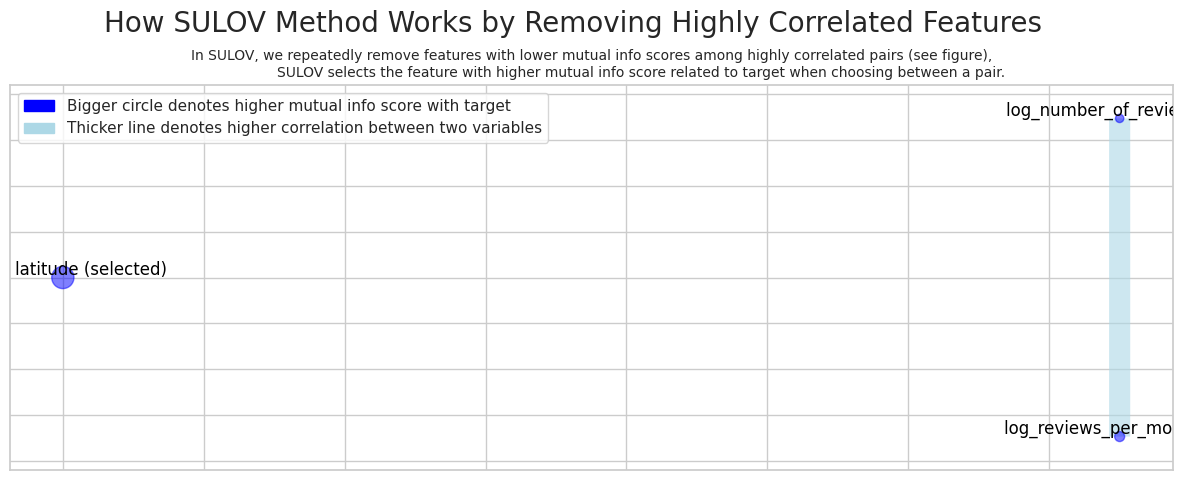

Splitting selected features into float and categorical (integer) variables:
    (5) float variables ...
    (6) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 11 
    Finding Important Features using Boosted Trees algorithm...
        using 11 variables...
        using 9 variables...
        using 7 variables...
        using 5 variables...
        using 3 variables...
Found 11 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  23228 , CV rows =  5808
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Performing MinMax scaling of

In [ ]:
from autoviml.Auto_ViML import Auto_ViML

automl_train = X_train_filtered.reset_index(drop=True).copy()
automl_train["log_price"] = np.log1p(
    y_train_filtered.to_numpy()
)

automl_val = X_val.reset_index(drop=True).copy()

print("Training shape:", automl_train.shape)
print("Validation shape:", automl_val.shape)

bagging_model, bagging_features, bagging_train_modified, bagging_val_modified = Auto_ViML(
    train=automl_train.copy(),
    target="log_price",
    test=automl_val.copy(),
    sample_submission="",
    hyper_param="RS",
    feature_reduction=True,
    scoring_parameter="",
    Boosting_Flag=False,
    KMeans_Featurizer=False,
    Binning_Flag=False,
    Add_Poly=0,
    Stacking_Flag=False,
    Imbalanced_Flag=False,
    GPU_flag=False,
    verbose=1
)

In [22]:
print("Returned model:", type(bagging_model).__name__)
print("Selected feature count:", len(bagging_features))
print("Validation output columns:")
print(bagging_val_modified.columns.tolist())

Returned model: RandomForestRegressor
Selected feature count: 11
Validation output columns:
['room_type', 'longitude', 'latitude', 'availability_365', 'has_no_reviews', 'log_calculated_host_listings_count', 'log_minimum_nights', 'log_number_of_reviews', 'cluster', 'neighbourhood_group', 'neighbourhood', 'log_price_predictions']


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

bagging_log_predictions = np.asarray(
    bagging_model.predict(
        bagging_val_modified[bagging_features]
    )
).reshape(-1)

bagging_predictions = np.maximum(
    np.expm1(bagging_log_predictions),
    0
)

actual_prices = y_val.to_numpy()

assert len(bagging_predictions) == len(actual_prices)
assert np.isfinite(bagging_predictions).all()

bagging_results = pd.DataFrame([{
    "model": "AutoViML Random Forest",
    "MAE": mean_absolute_error(
        actual_prices, bagging_predictions
    ),
    "RMSE": np.sqrt(
        mean_squared_error(actual_prices, bagging_predictions)
    )
}])

display(bagging_results.round(2))

display(pd.DataFrame({
    "actual_price": actual_prices,
    "predicted_price": bagging_predictions,
    "absolute_error": np.abs(actual_prices - bagging_predictions)
}).head(10).round(2))

,model,MAE,RMSE
0,AutoViML Random Forest,55.33,175.55


,actual_price,predicted_price,absolute_error
0,130,192.34,62.34
1,65,60.97,4.03
2,226,169.33,56.67
3,175,68.32,106.68
4,155,130.31,24.69
5,270,152.38,117.62
6,70,67.15,2.85
7,60,144.53,84.53
8,90,107.80,17.80
9,90,60.81,29.19


##############  D A T A   S E T  A N A L Y S I S  #######################
Training Set Shape = (29036, 13)
    Training Set Memory Usage = 2.88 MB
Test Set Shape = (9777, 12)
    Test Set Memory Usage = 0.90 MB
Single_Label Target: ['log_price']

################ Regression VISUALIZATION Started #####################
No shuffling of data set before training...
    Using RandomizedSearchCV for Hyper Parameter Tuning. This is 3X faster than GridSearchCV...
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  6
    Number of Integer-Categorical Columns =  1
    Number of String-Categorical Columns =  3
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  0
    Number of Numeric-Bo

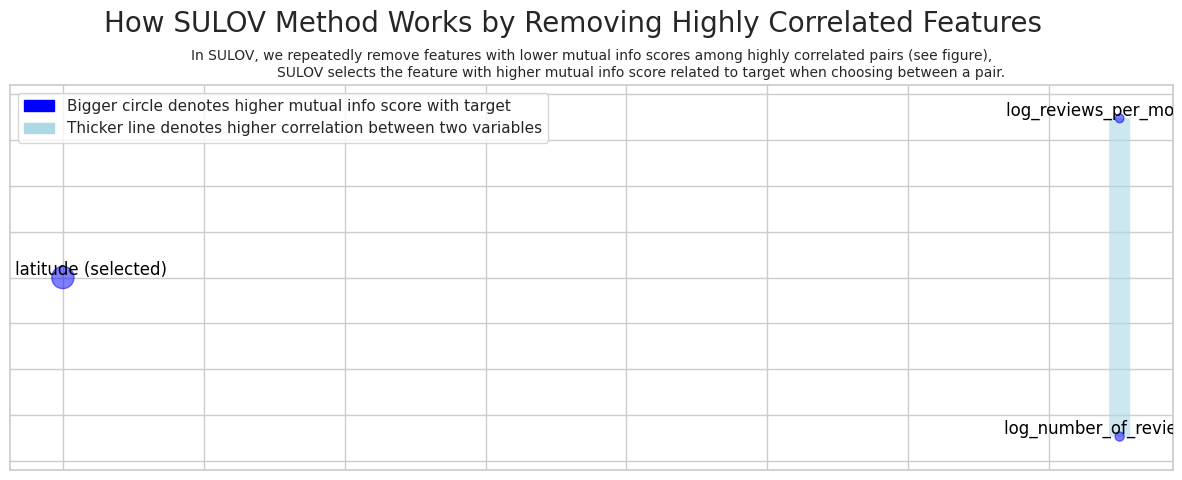

Splitting selected features into float and categorical (integer) variables:
    (5) float variables ...
    (6) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 11 
    Finding Important Features using Boosted Trees algorithm...
        using 11 variables...
        using 9 variables...
        using 7 variables...
        using 5 variables...
        using 3 variables...
Found 11 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  23228 , CV rows =  5808
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Skipping MinMax scaling sinc

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

Learning rate set to 0.025459
0:	learn: 0.6830850	test: 0.6993210	best: 0.6993210 (0)	total: 52.2ms	remaining: 6m 5s


500:	learn: 0.4381077	test: 0.4593934	best: 0.4593934 (500)	total: 2.33s	remaining: 30.2s
1000:	learn: 0.4243966	test: 0.4538730	best: 0.4538730 (1000)	total: 4.48s	remaining: 26.9s
1500:	learn: 0.4151184	test: 0.4511142	best: 0.4511118 (1494)	total: 6.63s	remaining: 24.3s
2000:	learn: 0.4077058	test: 0.4495149	best: 0.4495119 (1999)	total: 9.06s	remaining: 22.6s
2500:	learn: 0.4012674	test: 0.4484447	best: 0.4484442 (2499)	total: 12.5s	remaining: 22.5s
3000:	learn: 0.3956346	test: 0.4477789	best: 0.4477789 (3000)	total: 14.7s	remaining: 19.6s
3500:	learn: 0.3904540	test: 0.4471370	best: 0.4471308 (3499)	total: 16.9s	remaining: 16.9s
4000:	learn: 0.3857027	test: 0.4470380	best: 0.4469478 (3824)	total: 19.1s	remaining: 14.3s
4500:	learn: 0.3813617	test: 0.4468053	best: 0.4467520 (4352)	total: 21.2s	remaining: 11.8s
5000:	learn: 0.3772693	test: 0.4466337	best: 0.4466051 (4948)	total: 24.1s	remaining: 9.62s
5500:	learn: 0.3734129	test: 0.4467201	best: 0.4465954 (5055)	total: 27.2s	remaini

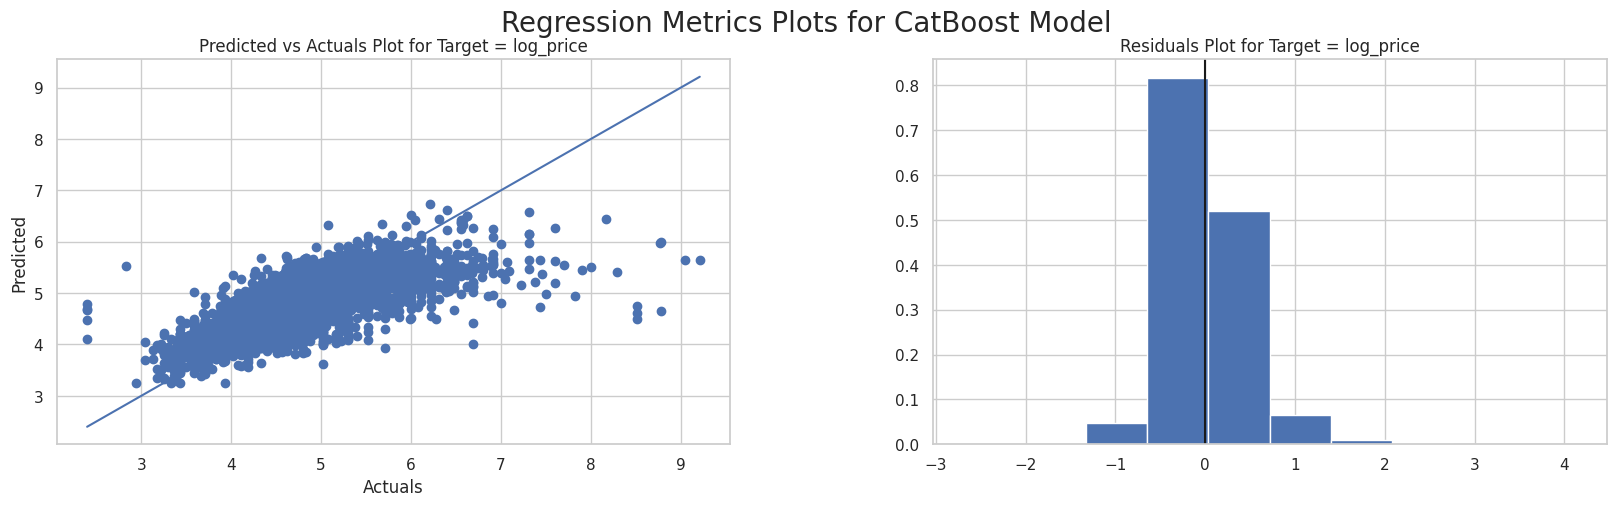

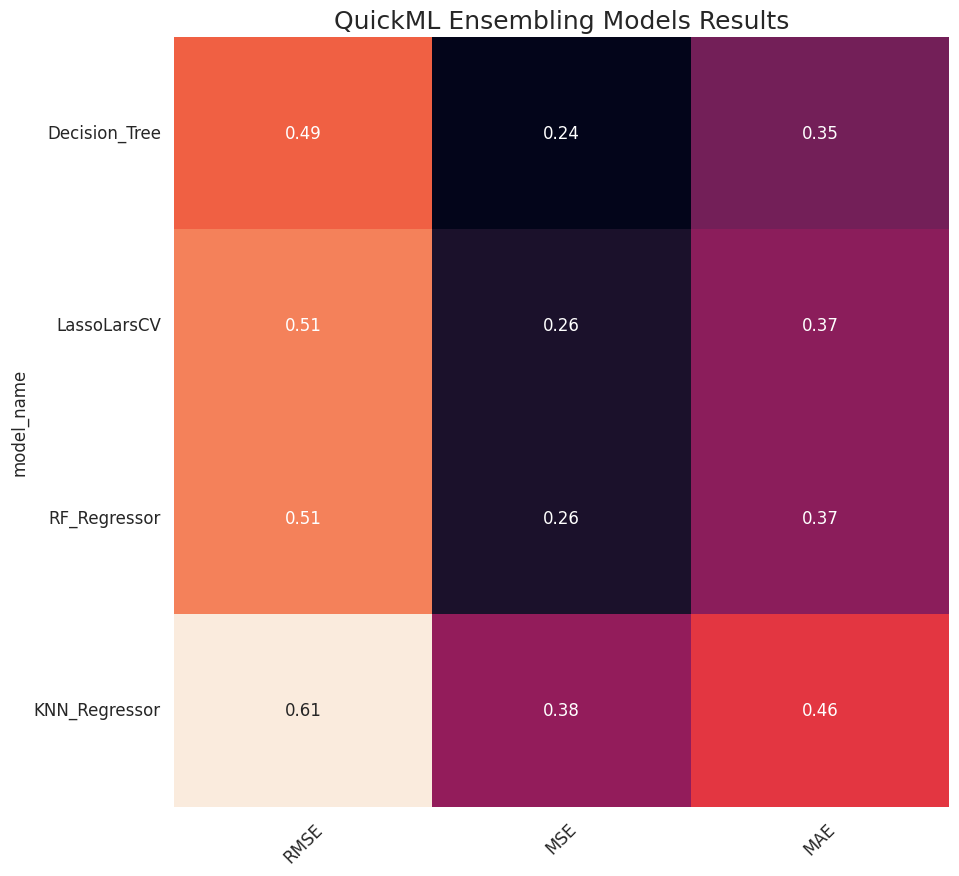

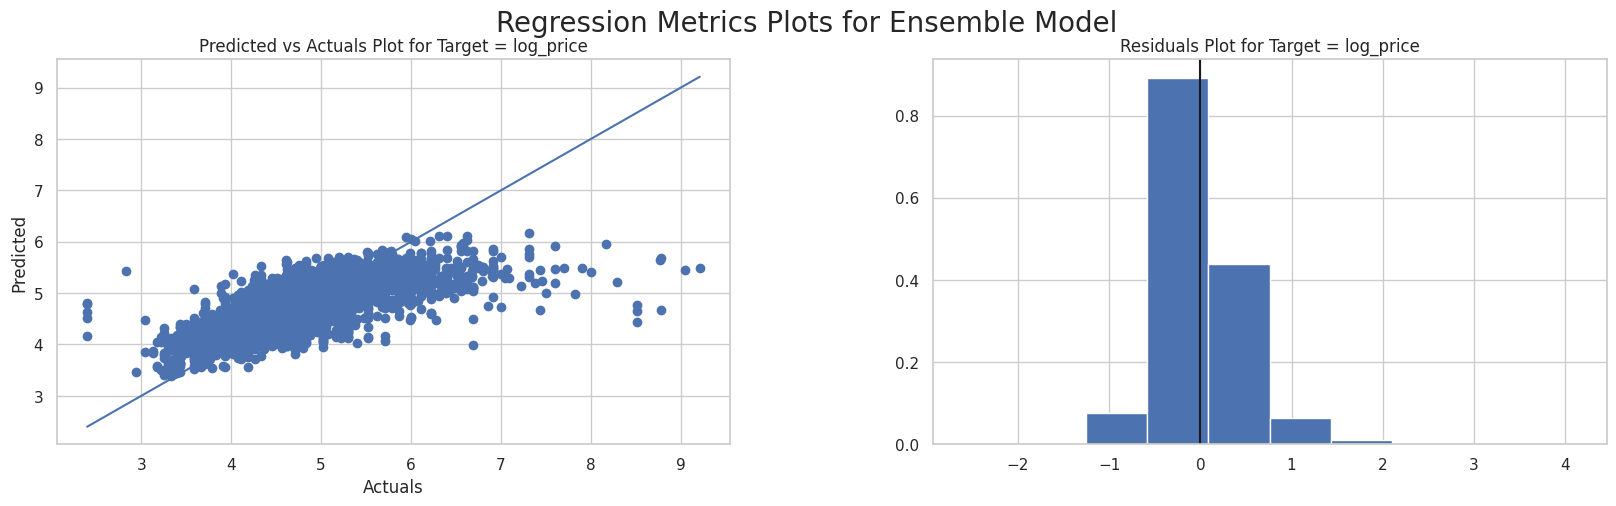

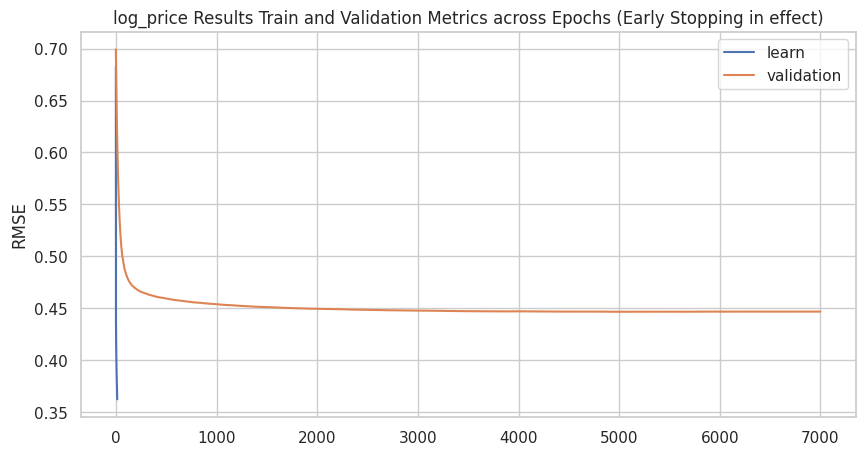

    Time taken for this Target (in seconds) = 43
    Binning_Flag set to False or there are no float vars in data set to be binned
    Setting best params for CatBoost model from Initial State since you cannot change params to a fitted Catboost model 
    Number of Categorical and Integer variables used in CatBoost training = 6
No MinMax scaling performed since scaling flag is set to false
###########################################################################
#####   F I N A L I Z I N G   M O D E L   O N    F U L L   T R A I N  #####
###########################################################################
0:	learn: 0.6864702	total: 6.81ms	remaining: 34.4s
500:	learn: 0.4402620	total: 3.78s	remaining: 34.3s
1000:	learn: 0.4276358	total: 6.61s	remaining: 26.8s
1500:	learn: 0.4191633	total: 9s	remaining: 21.3s
2000:	learn: 0.4125075	total: 11.4s	remaining: 17.4s
2500:	learn: 0.4066111	total: 13.8s	remaining: 14.1s
3000:	learn: 0.4014190	total: 17.3s	remaining: 11.8s
3500:	learn: 0

In [25]:
cat_model, cat_features, cat_train_modified, cat_val_modified = Auto_ViML(
    train=automl_train.copy(),
    target="log_price",
    test=automl_val.copy(),
    sample_submission="",
    hyper_param="RS",
    feature_reduction=True,
    scoring_parameter="",
    Boosting_Flag="CatBoost",
    KMeans_Featurizer=False,
    Binning_Flag=False,
    Add_Poly=0,
    Stacking_Flag=False,
    Imbalanced_Flag=False,
    GPU_flag=False,
    verbose=1
)

In [26]:
cat_log_predictions = np.asarray(
    cat_model.predict(cat_val_modified[cat_features])
).reshape(-1)

cat_predictions = np.maximum(np.expm1(cat_log_predictions), 0)

assert len(cat_predictions) == len(actual_prices)
assert np.isfinite(cat_predictions).all()

cat_results = pd.DataFrame([{
    "model": "AutoViML CatBoost",
    "MAE": mean_absolute_error(actual_prices, cat_predictions),
    "RMSE": np.sqrt(
        mean_squared_error(actual_prices, cat_predictions)
    )
}])

automl_comparison = pd.concat(
    [bagging_results, cat_results],
    ignore_index=True
).sort_values("MAE")

display(automl_comparison.round(2))

,model,MAE,RMSE
1,AutoViML CatBoost,52.89,163.79
0,AutoViML Random Forest,55.33,175.55


## AutoViML Model Comparison

AutoViML CatBoost achieved validation MAE of $52.89 and RMSE of $163.79,
compared with $55.33 and $175.55 for AutoViML Random Forest.

I selected the CatBoost configuration using validation MAE. It also had
lower RMSE. The XGBoost configuration failed because of a library
compatibility issue, so CatBoost served as the second successful
AutoViML model family.

AutoViML's internal training metrics refer to log-transformed price.
The comparison above measures prediction errors in dollars per night.

##############  D A T A   S E T  A N A L Y S I S  #######################
Training Set Shape = (29036, 13)
    Training Set Memory Usage = 2.88 MB
Test Set Shape = (9777, 12)
    Test Set Memory Usage = 0.90 MB
Single_Label Target: ['log_price']

################ Regression VISUALIZATION Started #####################
No shuffling of data set before training...
    Using RandomizedSearchCV for Hyper Parameter Tuning. This is 3X faster than GridSearchCV...
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  6
    Number of Integer-Categorical Columns =  1
    Number of String-Categorical Columns =  3
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  0
    Number of Numeric-Bo

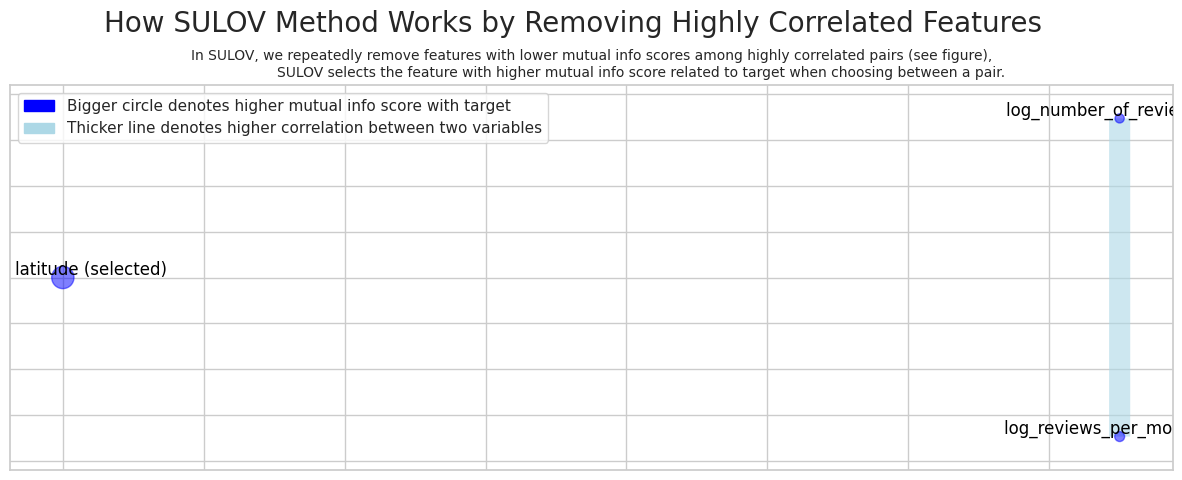

Splitting selected features into float and categorical (integer) variables:
    (5) float variables ...
    (6) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 11 
    Finding Important Features using Boosted Trees algorithm...
        using 11 variables...
        using 9 variables...
        using 7 variables...
        using 5 variables...
        using 3 variables...
Found 11 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  23228 , CV rows =  5808
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Skipping MinMax scaling sinc

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

Learning rate set to 0.025459
0:	learn: 0.6858407	test: 0.6874770	best: 0.6874770 (0)	total: 10.8ms	remaining: 1m 15s


500:	learn: 0.4361318	test: 0.4666289	best: 0.4666289 (500)	total: 2.62s	remaining: 33.9s
1000:	learn: 0.4228585	test: 0.4623096	best: 0.4623096 (1000)	total: 4.74s	remaining: 28.4s
1500:	learn: 0.4133726	test: 0.4596974	best: 0.4596974 (1500)	total: 6.89s	remaining: 25.3s
2000:	learn: 0.4064382	test: 0.4585624	best: 0.4585612 (1999)	total: 9.02s	remaining: 22.5s
2500:	learn: 0.4003467	test: 0.4578217	best: 0.4578208 (2456)	total: 11.5s	remaining: 20.6s
3000:	learn: 0.3948960	test: 0.4572422	best: 0.4572075 (2903)	total: 14.9s	remaining: 19.9s
3500:	learn: 0.3896888	test: 0.4569357	best: 0.4569051 (3470)	total: 17s	remaining: 17s
4000:	learn: 0.3850492	test: 0.4568362	best: 0.4568165 (3900)	total: 19.2s	remaining: 14.4s
4500:	learn: 0.3808049	test: 0.4568293	best: 0.4567563 (4464)	total: 21.4s	remaining: 11.9s
5000:	learn: 0.3766038	test: 0.4567662	best: 0.4567439 (4890)	total: 23.6s	remaining: 9.41s
5500:	learn: 0.3729220	test: 0.4568001	best: 0.4566559 (5126)	total: 26.4s	remaining: 

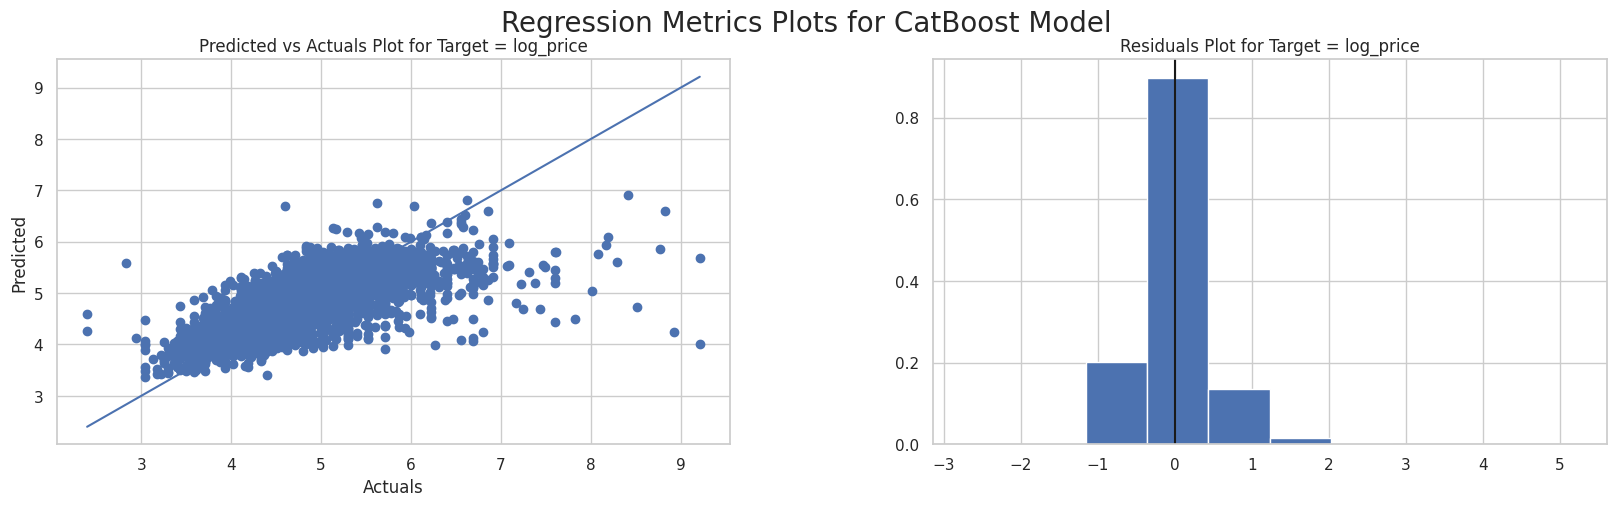

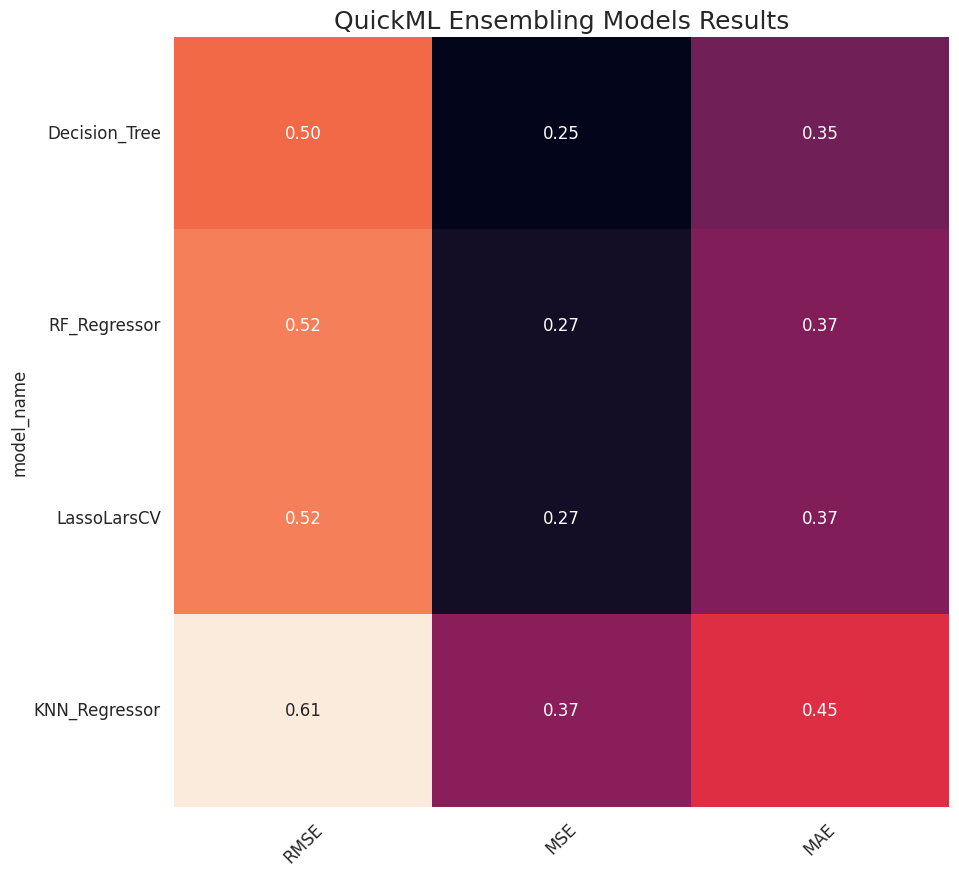

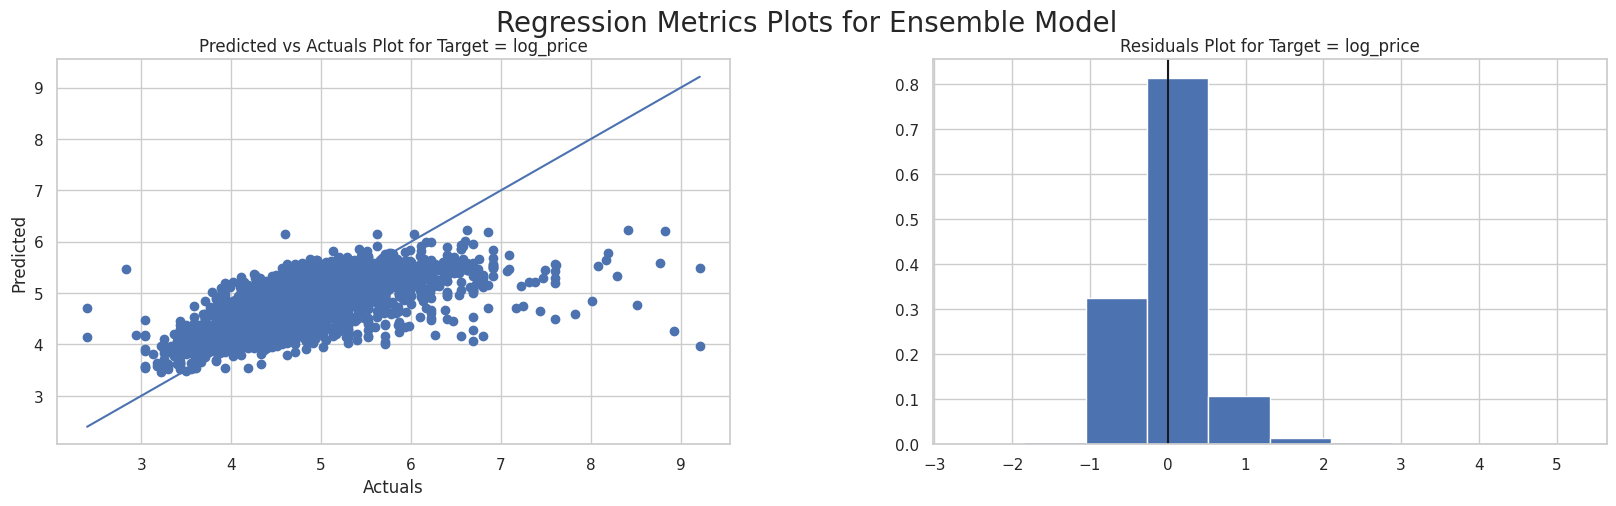

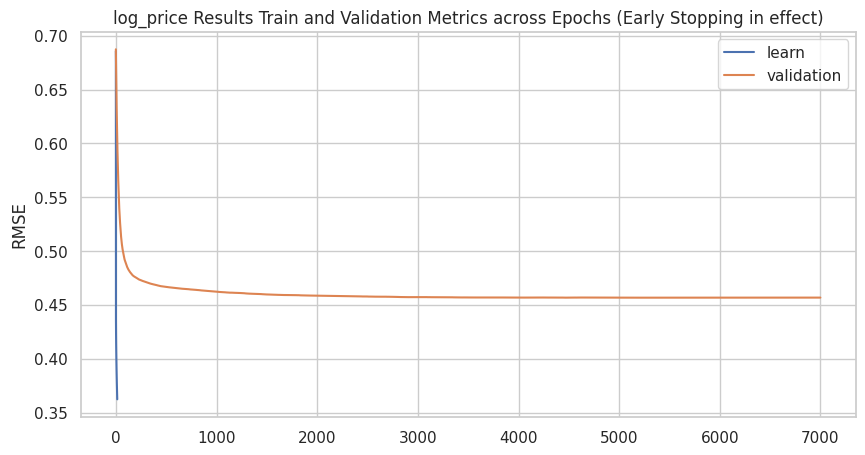

    Time taken for this Target (in seconds) = 43
    Binning_Flag set to False or there are no float vars in data set to be binned
    Setting best params for CatBoost model from Initial State since you cannot change params to a fitted Catboost model 
    Number of Categorical and Integer variables used in CatBoost training = 6
No MinMax scaling performed since scaling flag is set to false
###########################################################################
#####   F I N A L I Z I N G   M O D E L   O N    F U L L   T R A I N  #####
###########################################################################
0:	learn: 0.6863130	total: 7.13ms	remaining: 36.6s
500:	learn: 0.4403978	total: 2.62s	remaining: 24.2s
1000:	learn: 0.4278545	total: 6.61s	remaining: 27.2s
1500:	learn: 0.4192677	total: 9.19s	remaining: 22.2s
2000:	learn: 0.4125802	total: 11.6s	remaining: 18.1s
2500:	learn: 0.4066599	total: 14s	remaining: 14.7s
3000:	learn: 0.4017006	total: 16.4s	remaining: 11.6s
3500:	learn: 

In [27]:
X_test = build_model_features(test_df)
automl_test = X_test.reset_index(drop=True).copy()
y_test = test_df["price"].to_numpy()

final_model, final_features, final_train_modified, final_test_modified = Auto_ViML(
    train=automl_train.copy(),
    target="log_price",
    test=automl_test.copy(),
    sample_submission="",
    hyper_param="RS",
    feature_reduction=True,
    scoring_parameter="",
    Boosting_Flag="CatBoost",
    KMeans_Featurizer=False,
    Binning_Flag=False,
    Add_Poly=0,
    Stacking_Flag=False,
    Imbalanced_Flag=False,
    GPU_flag=False,
    verbose=1
)

In [28]:
test_log_predictions = np.asarray(
    final_model.predict(final_test_modified[final_features])
).reshape(-1)

test_predictions = np.maximum(
    np.expm1(test_log_predictions),
    0
)

assert len(test_predictions) == len(y_test)
assert np.isfinite(test_predictions).all()

test_baseline_predictions = np.full(
    len(y_test),
    y_train.median()
)

test_results = pd.DataFrame([
    {
        "model": "Training-median baseline",
        "MAE": mean_absolute_error(y_test, test_baseline_predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, test_baseline_predictions)
        )
    },
    {
        "model": "AutoViML CatBoost",
        "MAE": mean_absolute_error(y_test, test_predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, test_predictions)
        )
    }
])

display(test_results.round(2))

,model,MAE,RMSE
0,Training-median baseline,81.41,181.36
1,AutoViML CatBoost,54.32,152.39


## Final Test Results

On 9,777 held-out listings, the selected AutoViML CatBoost configuration
achieved MAE of $54.32 and RMSE of $152.39. The training-median baseline
achieved MAE of $81.41 and RMSE of $181.36.

CatBoost reduced MAE by approximately 33.3%. Its test MAE was close to
the validation MAE of $52.89. RMSE remained substantially higher than MAE,
indicating that some listings had large prediction errors.

These results describe held-out listings from the same 2019 NYC snapshot.
Performance on future listings or other cities remains unverified.

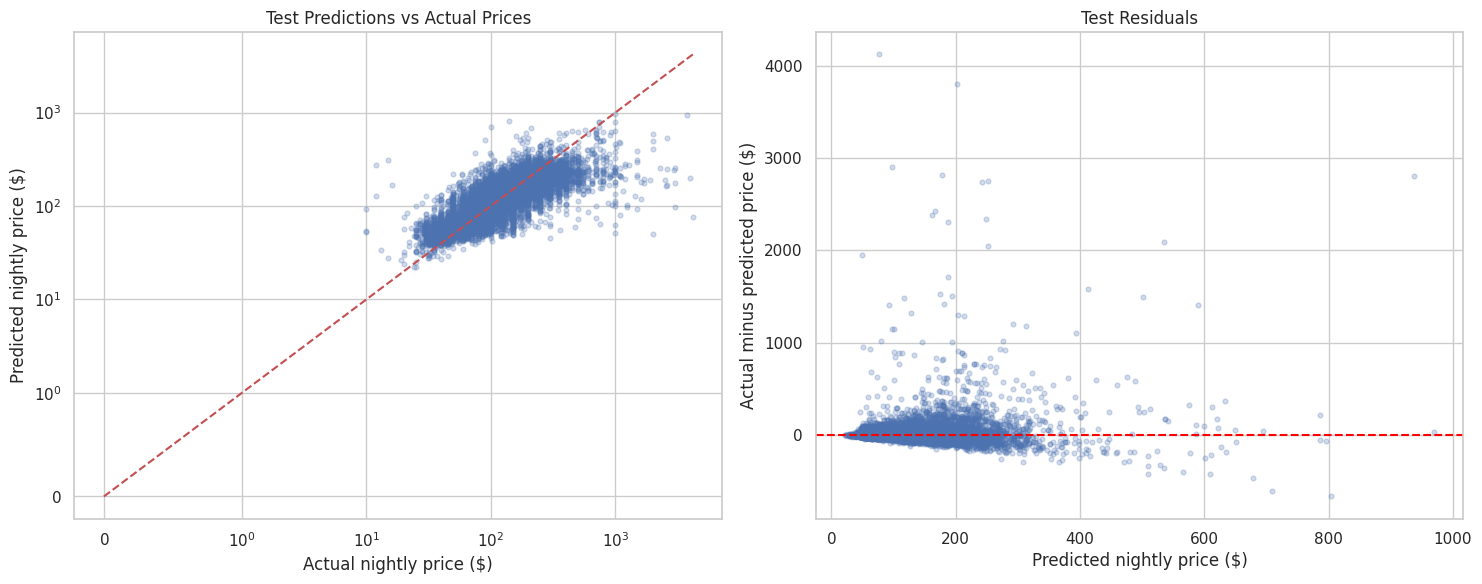

In [29]:
test_prediction_details = pd.DataFrame({
    "listing_id": test_df["id"].to_numpy(),
    "actual_price": y_test,
    "predicted_price": test_predictions
})

test_prediction_details["residual"] = (
    test_prediction_details["actual_price"]
    - test_prediction_details["predicted_price"]
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(
    y_test,
    test_predictions,
    alpha=0.25,
    s=12
)

upper_limit = max(y_test.max(), test_predictions.max())
axes[0].plot([0, upper_limit], [0, upper_limit], "r--")
axes[0].set_title("Test Predictions vs Actual Prices")
axes[0].set_xlabel("Actual nightly price ($)")
axes[0].set_ylabel("Predicted nightly price ($)")
axes[0].set_xscale("symlog", linthresh=1)
axes[0].set_yscale("symlog", linthresh=1)

axes[1].scatter(
    test_predictions,
    test_prediction_details["residual"],
    alpha=0.25,
    s=12
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Test Residuals")
axes[1].set_xlabel("Predicted nightly price ($)")
axes[1].set_ylabel("Actual minus predicted price ($)")

plt.tight_layout()
plt.show()

In [30]:
from pathlib import Path
from importlib.metadata import version
import json
import shutil
import sys
from google.colab import files

output_dir = Path("airbnb_artifacts")
output_dir.mkdir(exist_ok=True)

airbnb_clean.to_csv(output_dir / "cleaned_airbnb.csv", index=False)
split_summary.to_csv(output_dir / "split_summary.csv", index=False)
cluster_results.to_csv(output_dir / "cluster_scores.csv", index=False)
cluster_profile.to_csv(output_dir / "cluster_profiles.csv")

anomaly_audit.to_csv(output_dir / "training_anomaly_audit.csv", index=False)
automl_comparison.to_csv(
    output_dir / "automl_validation_results.csv",
    index=False
)
test_results.to_csv(output_dir / "final_test_results.csv", index=False)
test_prediction_details.to_csv(
    output_dir / "test_predictions.csv",
    index=False
)

split_assignments = pd.concat([
    train_df[["id"]].assign(split="train"),
    val_df[["id"]].assign(split="validation"),
    test_df[["id"]].assign(split="test")
])
split_assignments.to_csv(
    output_dir / "listing_split_assignments.csv",
    index=False
)

environment = {
    "python": sys.version,
    "packages": {
        package: version(package)
        for package in [
            "numpy", "pandas", "scikit-learn",
            "autoviml", "catboost", "xgboost"
        ]
    },
    "selected_model": "AutoViML CatBoost",
    "target": "log1p(price)",
    "selected_features": list(final_features)
}

(output_dir / "environment_and_model.json").write_text(
    json.dumps(environment, indent=2)
)

fig.savefig(
    output_dir / "test_prediction_diagnostics.png",
    dpi=200,
    bbox_inches="tight"
)

archive = shutil.make_archive(
    "airbnb_artifacts",
    "zip",
    root_dir=output_dir
)
files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>